In [30]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [3]:
arquivo_entrada = Path("../data/raw/ibovespa_raw.csv")

# Carregar o dataset
df = pd.read_csv(arquivo_entrada, parse_dates=["Date"])

# Ordenar pela data, da mais antiga pra mais recente
df = df.sort_values("Date").reset_index(drop=True)

# Conferir a estrutura
print("### Conferindo a estrutura ###\n")
print("Dimensões: ", df.shape)
print("\nTipos das colunas:")
print(df.dtypes)

print("\nPrimeiras linhas:")
display(df.head())

print("\nÚltimas linhas:")
display(df.tail())

print("Datas em ordem cronológica: ", df["Date"].is_monotonic_increasing)
print("Datas duplicadas: ", df["Date"].duplicated().sum())

print("\nEstatísticas descritivas das variáveis numéricas")
display(df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].describe().round(2))

### Conferindo a estrutura ###

Dimensões:  (3965, 7)

Tipos das colunas:
Date         datetime64[us]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object

Primeiras linhas:


,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-01-04,68587.0,70081.0,68587.0,70045.0,70045.0,1655400
1,2010-01-05,70046.0,70595.0,69928.0,70240.0,70240.0,1984200
2,2010-01-06,70237.0,70937.0,70016.0,70729.0,70729.0,2243600
3,2010-01-07,70723.0,70723.0,70045.0,70451.0,70451.0,1555000
4,2010-01-08,70455.0,70766.0,70158.0,70263.0,70263.0,1634400



Últimas linhas:


,Date,Open,High,Low,Close,Adj Close,Volume
3960,2025-12-22,158480.0,158634.0,157306.0,158142.0,158142.0,8424000
3961,2025-12-23,158144.0,160456.0,158144.0,160456.0,160456.0,6569800
3962,2025-12-26,160456.0,160913.0,159359.0,160897.0,160897.0,4790000
3963,2025-12-29,160897.0,161133.0,159702.0,160490.0,160490.0,5605600
3964,2025-12-30,160491.0,162075.0,160491.0,161125.0,161125.0,5870100


Datas em ordem cronológica:  True
Datas duplicadas:  0

Estatísticas descritivas das variáveis numéricas


,Open,High,Low,Close,Adj Close,Volume
count,3965.00,3965.00,3965.00,3965.00,3965.00,3965.00
mean,84678.39,85423.74,83951.36,84699.68,84699.68,6102611.40
std,30012.92,30169.03,29883.34,30036.52,30036.52,4083514.17
min,37501.00,38031.00,37046.00,37497.00,37497.00,0.00
25%,57561.00,58114.00,57068.00,57550.00,57550.00,3026100.00
50%,74656.00,75470.00,74145.00,74657.00,74657.00,4360000.00
75%,111995.00,113057.00,110935.00,111996.00,111996.00,9119300.00
max,164461.00,165036.00,161759.00,164456.00,164456.00,26029300.00


In [4]:
# Criar a pasta para armazenar os gráficos

pasta_graficos = Path("../reports/figures")
pasta_graficos.mkdir(parents=True, exist_ok=True)

if pasta_graficos.exists() and pasta_graficos.is_dir():
    print(f"SUCESSO: O diretório {pasta_graficos} foi criado ou já existia")
else: 
    print(f"ERRO: O diretório {pasta_graficos} não foi encontrado")

SUCESSO: O diretório ..\reports\figures foi criado ou já existia


SUCESSO: Gráfico salvo com sucesso em: ..\reports\figures\evolucao_ibovespa.png
Tamanho do arquivo: 113.96 KB


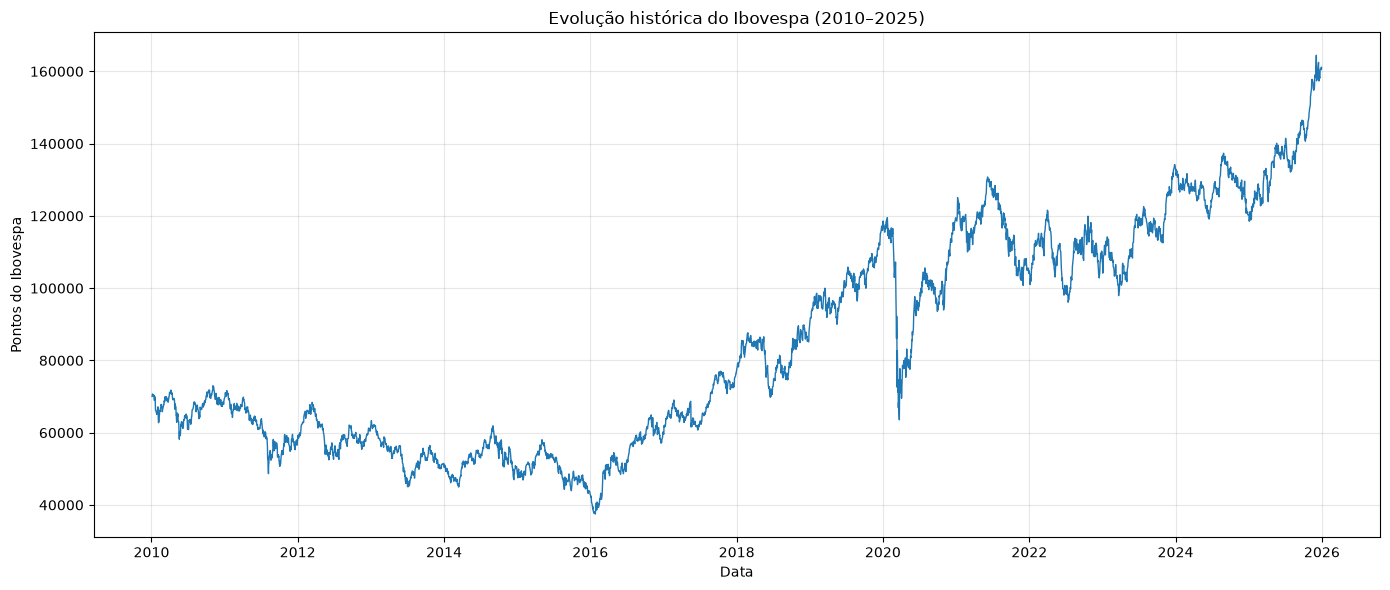

In [5]:
# Criação do gráfico de fechamento histórico
plt.figure(figsize=(14, 6))
plt.plot(df["Date"], df["Close"], linewidth=1)

plt.title("Evolução histórica do Ibovespa (2010–2025)")
plt.xlabel("Data")
plt.ylabel("Pontos do Ibovespa")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save do gráfico
caminho_grafico1 = pasta_graficos / "evolucao_ibovespa.png"
plt.savefig(
    caminho_grafico1,
    dpi=150,
    bbox_inches="tight"
)

if caminho_grafico1.is_file() and caminho_grafico1.stat().st_size > 0:
    print(f"SUCESSO: Gráfico salvo com sucesso em: {caminho_grafico1}")
    print(f"Tamanho do arquivo: {caminho_grafico1.stat().st_size / 1024:.2f} KB")
else:
    print(f"ERRO: O arquivo do gráfico não foi gerado ou está vazio.")

plt.show()
plt.close()

In [2]:
# Criação do gráfico de distribuição dos retornos diários

# Variação percentual entre fechamentos consecutivos
df["Retorno_Diario"] = df["Close"].pct_change() * 100

# Resumo estatístico dos retornos
print("Resumo estatístico dos retornos:")
display(df["Retorno_Diario"].describe().round(4))

# Visualizar a distribuição dos retornos diários
plt.figure(figsize=(12, 5))
plt.hist(df["Retorno_Diario"].dropna(), bins=80)

plt.title("Distribuição dos retornos diários do Ibovespa")
plt.xlabel("Retorno diário (%)")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

caminho_grafico2 = pasta_graficos / "distribuicao_retornos_diarios.png"
plt.savefig(
    caminho_grafico2,
    dpi=150,
    bbox_inches="tight"
)

if caminho_grafico2.is_file() and caminho_grafico2.stat().st_size > 0:
    print(f"\nSUCESSO: Gráfico salvo com sucesso em: {caminho_grafico2}")
    print(f"Tamanho do arquivo: {caminho_grafico2.stat().st_size / 1024:.2f} KB")
else:
    print(f"ERRO: O arquivo do gráfico não foi gerado ou está vazio.")

plt.show()
plt.close()

NameError: name 'df' is not defined

# Criação das variáveis explicativas:

- Retorno_Diario: Variação percentual do fechamento em relação ao pregão anterior
- Retorno_5d: Variação acumulada nos últimos cinco pregões
- Retorno_10d: Variação acumulada nos últimos dez pregões
- Media_Retorno_5d: Média dos retornos diários dos últimos cinco pregões
- Volatilidade_5d: Desvio padrão dos retornos diários dos últimos cinco pregões
- Variacao_Intradiaria: Variação percentual entre abertura e fechamento do pregão
- Amplitude_Diaria: Diferença percentual entre máxima e mínima do pregão


In [1]:
# Criar uma cópia pra preservar os dados brutos
df_modelo = df.copy()

# Retorno diário em porcentagem
df_modelo["Retorno_Diario"] = df_modelo["Close"].pct_change() * 100

# Retornos acumulados dos ultimos 5 e 10 pregoes
df_modelo["Retorno_5d"] = (
    df_modelo["Close"].pct_change(periods=5) * 100
)
df_modelo["Retorno_10d"] = (
    df_modelo["Close"].pct_change(periods=10) * 100
)

# Media e desvio padrão dos retornos dos ultimos 5 pregões
df_modelo["Media_Retorno_5d"] =(
    df_modelo["Retorno_Diario"].rolling(window=5).mean()
)
df_modelo["Volatilidade_5d"] =(
    df_modelo["Retorno_Diario"].rolling(window=5).std()
)

# Variação entre abertura e fechamento 
df_modelo["Variacao_Intradiaria"] =(
    (df_modelo["Close"] / df_modelo["Open"] - 1) * 100
)

# Amplitude entre máxima e minima do pregão
df_modelo["Amplitude_Diaria"] = (
    (df_modelo["High"] / df_modelo["Low"] -1) * 100
)

display(df_modelo.head(12))


NameError: name 'df' is not defined

In [27]:
# Criação da classificação que queremos prever

# Fechamento de cinco pregões à frente
df_modelo["Fechamento_Futuro_5d"] = df_modelo["Close"].shift(-5)

# Criar o target somente quando existe informação futura
df_modelo["Direcao_Futura"] = pd.NA

# ALTA = 1
df_modelo.loc[
    df_modelo["Fechamento_Futuro_5d"] > df_modelo["Close"],
    "Direcao_Futura"
] = 1

# QUEDA = 0
df_modelo.loc[
    df_modelo["Fechamento_Futuro_5d"] < df_modelo["Close"],
    "Direcao_Futura"
] = 0

# Identificar empates
empatados = (
    df_modelo["Fechamento_Futuro_5d"].notna()
    & (df_modelo["Fechamento_Futuro_5d"] == df_modelo["Close"])
)

print("Casos com fechamento igual:", int(empatados.sum()))
print("Casos sem informação futura:", int(
    df_modelo["Fechamento_Futuro_5d"].isna().sum()
))
print("Ultimas linhas sem fechamento futuro:")
display(df_modelo.tail(10))


Casos com fechamento igual: 0
Casos sem informação futura: 5
Ultimas linhas sem fechamento futuro:


,Date,Open,High,Low,Close,Adj Close,Volume,Retorno_Diario,Retorno_5d,Retorno_10d,Media_Retorno_5d,Volatilidade_5d,Variacao_Intradiaria,Amplitude_Diaria,Fechamento_Futuro_5d,Direcao_Futura
3955,2025-12-15,160766.0,163073.0,160766.0,162482.0,162482.0,8229000,1.067390,2.715141,2.440562,0.538393,0.541526,1.067390,1.435005,158142.0,0
3956,2025-12-16,162482.0,162482.0,158558.0,158578.0,158578.0,9920300,-2.402728,0.377894,-1.560599,0.083892,1.444238,-2.402728,2.474804,160456.0,1
3957,2025-12-17,158578.0,158611.0,156351.0,157327.0,157327.0,11344300,-0.788886,-1.098853,-2.737473,-0.212383,1.440117,-0.788886,1.445466,160897.0,1
3958,2025-12-18,157327.0,158496.0,157124.0,157923.0,157923.0,7800100,0.378829,-0.795281,-3.972491,-0.150950,1.461654,0.378829,0.873196,160490.0,1
3959,2025-12-19,157928.0,159552.0,157906.0,158473.0,158473.0,9946500,0.348271,-1.426297,0.701536,-0.279425,1.360990,0.345094,1.042392,161125.0,1
3960,2025-12-22,158480.0,158634.0,157306.0,158142.0,158142.0,8424000,-0.208868,-2.671065,-0.028447,-0.534676,1.148311,-0.213276,0.844214,NaN,<NA>
3961,2025-12-23,158144.0,160456.0,158144.0,160456.0,160456.0,6569800,1.463242,1.184275,1.566644,0.238517,0.834775,1.461959,1.461959,NaN,<NA>
3962,2025-12-26,160456.0,160913.0,159359.0,160897.0,160897.0,4790000,0.274842,2.269159,1.145372,0.451263,0.613770,0.274842,0.975157,NaN,<NA>
3963,2025-12-29,160897.0,161133.0,159702.0,160490.0,160490.0,5605600,-0.252957,1.625476,0.817268,0.324906,0.692406,-0.252957,0.896044,NaN,<NA>
3964,2025-12-30,160491.0,162075.0,160491.0,161125.0,161125.0,5870100,0.395663,1.673471,0.223306,0.334384,0.693129,0.395038,0.986971,NaN,<NA>


In [24]:
# Preparação da base que será usada pelos modelos

# Definição das variáveis que serão utilizadas pelos modelos
features = [
    "Retorno_Diario",
    "Retorno_5d",
    "Retorno_10d",
    "Media_Retorno_5d",
    "Volatilidade_5d",
    "Variacao_Intradiaria",
    "Amplitude_Diaria",
]

colunas_saida = ["Date"] + features + ["Direcao_Futura"]

# Excluir valores empatados, linhas sem histórico suficiente e linhas sem alvo futuro
df_preparado = df_modelo.loc[
    ~empatados,
    colunas_saida
].dropna().copy()

In [31]:
# Ultima validação antes de criar o arquivo

print("Distribuição absoluta:")
print(df_preparado["Direcao_Futura"].value_counts())

print("\nDistribuição percentual:")
print(
    (df_preparado["Direcao_Futura"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nValores ausentes:")
print(df_preparado.isna().sum())

print("\nValores infinitos:")
print(np.isinf(df_preparado.select_dtypes(include="number")).sum())

Distribuição absoluta:
Direcao_Futura
1    2082
0    1868
Name: count, dtype: int64

Distribuição percentual:
Direcao_Futura
1    52.71
0    47.29
Name: proportion, dtype: float64

Valores ausentes:
Date                    0
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
Direcao_Futura          0
dtype: int64

Valores infinitos:
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
dtype: int64


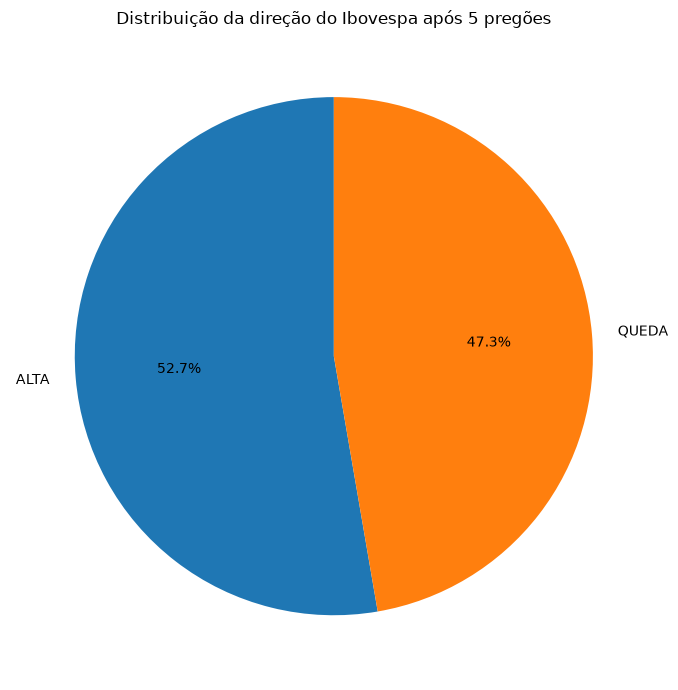

In [35]:
# Criação do gráfico de distribuição da direção futura do ibovespa

# Distribuição da direção futura
contagem_target = df_preparado["Direcao_Futura"].map({
    0: "QUEDA",
    1: "ALTA"
}).value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    contagem_target,
    labels=contagem_target.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribuição da direção do Ibovespa após 5 pregões")

plt.tight_layout()

plt.savefig(
    pasta_graficos / "distribuicao_target.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [9]:
# Criação do diretório de saída

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

if processed_dir.exists() and processed_dir.is_dir():
    print(f"SUCESSO: O diretório {processed_dir} foi criado ou já existia")
else: 
    print(f"ERRO: O diretório {processed_dir} não foi encontrado")

SUCESSO: O diretório ..\data\processed foi criado ou já existia


In [37]:
# Criação do arquivo e save da base preparada
arquivo_processado = processed_dir / "ibovespa_features.csv"
df_preparado.to_csv(arquivo_processado, index=False)

if arquivo_processado.exists():
    print(f"Arquivo salvo em {arquivo_processado.resolve()}")
else: 
    print("O arquivo não foi criado")

print("\nDimensões da base preparada:", df_preparado.shape)

Arquivo salvo em C:\Users\markn\GitHub\LM_Projects\classificacao-volatibilidade-ibovespa\data\processed\ibovespa_features.csv

Dimensões da base preparada: (3950, 9)
